In [54]:
#=================================================
# Multinomial Naive Bayes - Complete ML Project
#=================================================

# 1. IMPORT LIBRARIES

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score,precision_score,recall_score,f1_score,confusion_matrix,classification_report)

In [55]:
df = pd.read_csv("/content/sentiment_dataset.csv")
df

,sentiment,review,rating,review_length,word_count
0,positive,@athena422 Right on...I saw 'Ryche in Vegas at...,5,94,18
1,positive,@Cowbelly Enjoy your time at Pike's Place Mark...,5,121,22
2,positive,@Triciepop Yall goin to Vegas? Make sure yall ...,5,90,19
3,positive,im glad you had a good time i wntd to do somet...,4,89,23
4,positive,@Soraspsp now that summer is here you can come...,5,85,17
5,positive,DanniAsheOnline I think that would work nicely...,5,106,19
6,positive,@catharinamcfly think of London and you'll sur...,5,130,22
7,positive,Hey @daughter_4oprah! tomorrow is your mom's b...,5,124,22
8,positive,omg! well..here is the best news of all time i...,5,105,18
9,positive,Just built a shelf for my xbox http://twitpic....,4,55,8


In [56]:
print("\n========== DATASET LOADED ==========")
print(df.head())


========== DATASET LOADED ==========
  sentiment                                             review  rating  \
0  positive  @athena422 Right on...I saw 'Ryche in Vegas at...       5   
1  positive  @Cowbelly Enjoy your time at Pike's Place Mark...       5   
2  positive  @Triciepop Yall goin to Vegas? Make sure yall ...       5   
3  positive  im glad you had a good time i wntd to do somet...       4   
4  positive  @Soraspsp now that summer is here you can come...       5   

   review_length  word_count  
0             94          18  
1            121          22  
2             90          19  
3             89          23  
4             85          17  


In [57]:
print("\n========== DATASET SHAPE ==========")
print(df.shape)


========== DATASET SHAPE ==========
(40, 5)


In [58]:
print("\n========== COLUMN NAMES ==========")
print(df.columns.tolist())


========== COLUMN NAMES ==========
['sentiment', 'review', 'rating', 'review_length', 'word_count']


In [59]:
print("\n========== DATA TYPES ==========")
print(df.dtypes)


========== DATA TYPES ==========
sentiment        object
review           object
rating            int64
review_length     int64
word_count        int64
dtype: object


In [ ]:
print("\n========== DATASET INFORMATION ==========")
df.info()


========== DATASET INFORMATION ==========
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40 entries, 0 to 39
Data columns (total 5 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   sentiment      40 non-null     object
 1   review         40 non-null     object
 2   rating         40 non-null     int64 
 3   review_length  40 non-null     int64 
 4   word_count     40 non-null     int64 
dtypes: int64(3), object(2)
memory usage: 1.7+ KB


In [60]:
print("\n========== MISSING VALUES ==========")
print(df.isnull().sum())


========== MISSING VALUES ==========
sentiment        0
review           0
rating           0
review_length    0
word_count       0
dtype: int64


In [61]:
print("\n========== REMOVE DUPLICATES ==========")
df = df.drop_duplicates()


========== REMOVE DUPLICATES ==========


In [62]:
#HANDLING MISSING VALUES
df = df.dropna(subset=['review', 'sentiment'])

In [63]:
#Remove Extra Spaces
df['review'] = df['review'].str.strip()

In [64]:
#Remove Empty Records
df = df[df['review'] != '']

In [65]:
#convert text into Lowercase
df['review'] = df['review'].str.lower()
df['sentiment'] = df['sentiment'].str.lower().str.strip()

In [66]:
#convert datatypes
df['rating'] = pd.to_numeric(df['rating'], errors='coerce')

In [67]:
df = df.reset_index(drop=True)

print("Final Dataset Shape:", df.shape)

print("Missing Values:")
print(df.isnull().sum())

display(df.head(10))

Final Dataset Shape: (40, 5)
Missing Values:
sentiment        0
review           0
rating           0
review_length    0
word_count       0
dtype: int64


,sentiment,review,rating,review_length,word_count
0,positive,@athena422 right on...i saw 'ryche in vegas at...,5,94,18
1,positive,@cowbelly enjoy your time at pike's place mark...,5,121,22
2,positive,@triciepop yall goin to vegas? make sure yall ...,5,90,19
3,positive,im glad you had a good time i wntd to do somet...,4,89,23
4,positive,@soraspsp now that summer is here you can come...,5,85,17
5,positive,danniasheonline i think that would work nicely...,5,106,19
6,positive,@catharinamcfly think of london and you'll sur...,5,130,22
7,positive,hey @daughter_4oprah! tomorrow is your mom's b...,5,124,22
8,positive,omg! well..here is the best news of all time i...,5,105,18
9,positive,just built a shelf for my xbox http://twitpic....,4,55,8


In [68]:
print("\n========== DUPLICATE ROWS ==========")
print("Number of duplicates:", df.duplicated().sum())


========== DUPLICATE ROWS ==========
Number of duplicates: 0


In [69]:
print("\n========== STATISTICAL SUMMARY ==========")
print(df.describe())



========== STATISTICAL SUMMARY ==========
          rating  review_length  word_count
count  40.000000      40.000000   40.000000
mean    3.075000      90.650000   15.975000
std     1.759771      34.011725    6.442995
min     1.000000      17.000000    4.000000
25%     1.000000      65.000000   10.750000
50%     3.000000      92.000000   17.500000
75%     5.000000     119.500000   21.000000
max     5.000000     146.000000   28.000000


In [70]:
print("\n========== TARGET DISTRIBUTION ==========")
print(df["sentiment"].value_counts())


========== TARGET DISTRIBUTION ==========
sentiment
positive    20
negative    20
Name: count, dtype: int64


In [71]:
print("\n========== TARGET PERCENTAGE ==========")
print(
    df["sentiment"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)


========== TARGET PERCENTAGE ==========
sentiment
positive    50.0
negative    50.0
Name: proportion, dtype: float64


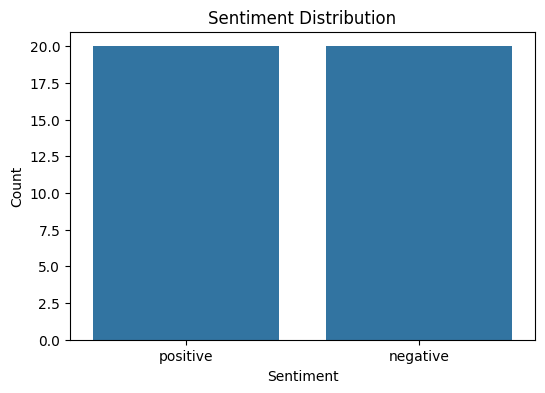

In [72]:
#   BAR CHART
plt.figure(figsize=(6,4))

sns.countplot(data=df, x='sentiment')

plt.title('Sentiment Distribution')
plt.xlabel('Sentiment')
plt.ylabel('Count')

plt.show()

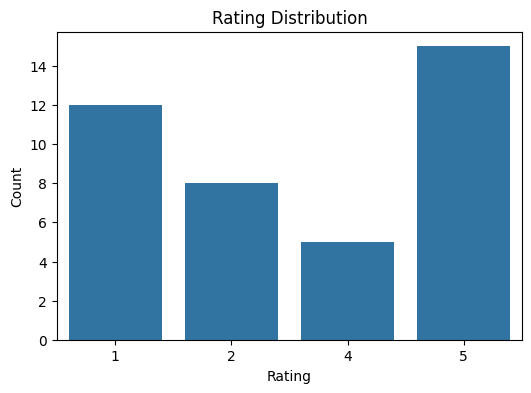

In [73]:
# Rating Distribution
plt.figure(figsize=(6,4))

sns.countplot(data=df, x='rating')

plt.title('Rating Distribution')
plt.xlabel('Rating')
plt.ylabel('Count')

plt.show()

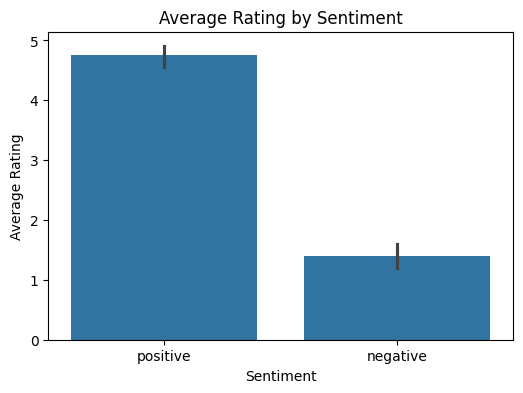

In [74]:
plt.figure(figsize=(6,4))

sns.barplot(data=df, x='sentiment', y='rating')

plt.title('Average Rating by Sentiment')
plt.xlabel('Sentiment')
plt.ylabel('Average Rating')

plt.show()

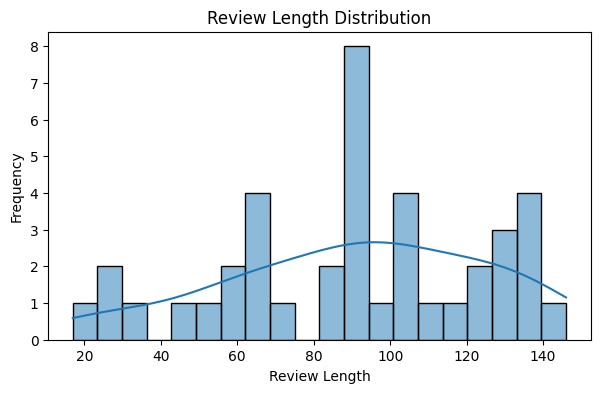

In [75]:
plt.figure(figsize=(7,4))

sns.histplot(data=df, x='review_length', bins=20, kde=True)

plt.title('Review Length Distribution')
plt.xlabel('Review Length')
plt.ylabel('Frequency')

plt.show()

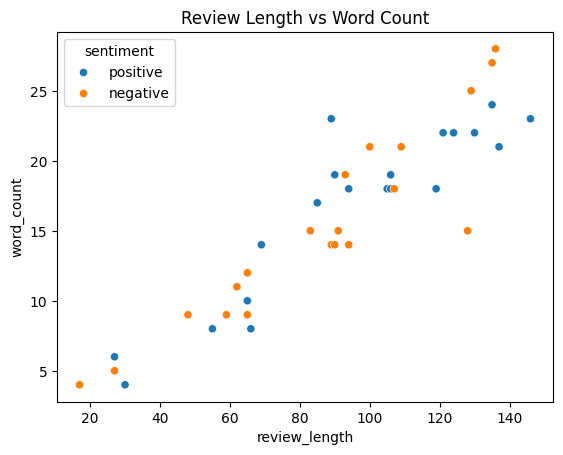

In [90]:
#Review Length vs Word Count

sns.scatterplot(data=df, x='review_length',
                y='word_count', hue='sentiment')
plt.title("Review Length vs Word Count")
plt.show()

In [76]:
X = df["review"]
y = df["sentiment"]

In [77]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

In [78]:
print("\n========== TRAIN/TEST SHAPE ==========")
print("X_train:", X_train.shape)
print("X_test :", X_test.shape)
print("y_train:", y_train.shape)
print("y_test :", y_test.shape)


========== TRAIN/TEST SHAPE ==========
X_train: (32,)
X_test : (8,)
y_train: (32,)
y_test : (8,)


In [79]:
if df.isnull().sum().sum() == 0 and df.duplicated().sum() == 0:
    print("Dataset Validation Successful")
else:
    print("Dataset Needs Further Cleaning")

Dataset Validation Successful


In [80]:
vectorizer = CountVectorizer()
vectorizer = CountVectorizer(max_features=5000, stop_words="english")
X_train_vectorized = vectorizer.fit_transform(X_train)
X_test_vectorized = vectorizer.transform(X_test)

In [81]:

# MULTINOMIAL NAIVE BAYES

model = MultinomialNB()
model.fit(X_train_vectorized, y_train)

MultinomialNB()

In [82]:
y_pred = model.predict(X_test_vectorized)

In [83]:
#Evaluation
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, average="weighted", zero_division=0)
recall = recall_score(y_test, y_pred, average="weighted", zero_division=0)
f1 = f1_score(y_test, y_pred, average="weighted", zero_division=0)

#Print Datas
print(f"Accuracy: {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")
print(f"F1-Score: {f1:.4f}")

Accuracy: 0.7500
Precision: 0.8333
Recall: 0.7500
F1-Score: 0.7333


In [84]:
#Classification Report
print("\n========== CLASSIFICATION REPORT ==========")
print(
    classification_report(
        y_test,
        y_pred,
        zero_division=0
    )
)


========== CLASSIFICATION REPORT ==========
              precision    recall  f1-score   support

    negative       1.00      0.50      0.67         4
    positive       0.67      1.00      0.80         4

    accuracy                           0.75         8
   macro avg       0.83      0.75      0.73         8
weighted avg       0.83      0.75      0.73         8



In [85]:
#Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
print("\n========== CONFUSION MATRIX ==========")
print(cm)


========== CONFUSION MATRIX ==========
[[2 2]
 [0 4]]


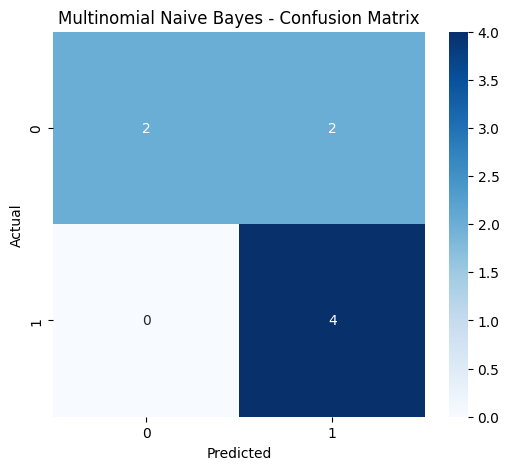

In [86]:
# Heatmap
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.title("Multinomial Naive Bayes - Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [91]:
# Numerical Values

numeric_features = [
    "rating",
    "review_length",
    "word_count"
]

print("\n========== NUMERICAL FEATURES ==========")
print(df[numeric_features].describe())


========== NUMERICAL FEATURES ==========
          rating  review_length  word_count
count  40.000000      40.000000   40.000000
mean    3.075000      90.650000   15.975000
std     1.759771      34.011725    6.442995
min     1.000000      17.000000    4.000000
25%     1.000000      65.000000   10.750000
50%     3.000000      92.000000   17.500000
75%     5.000000     119.500000   21.000000
max     5.000000     146.000000   28.000000


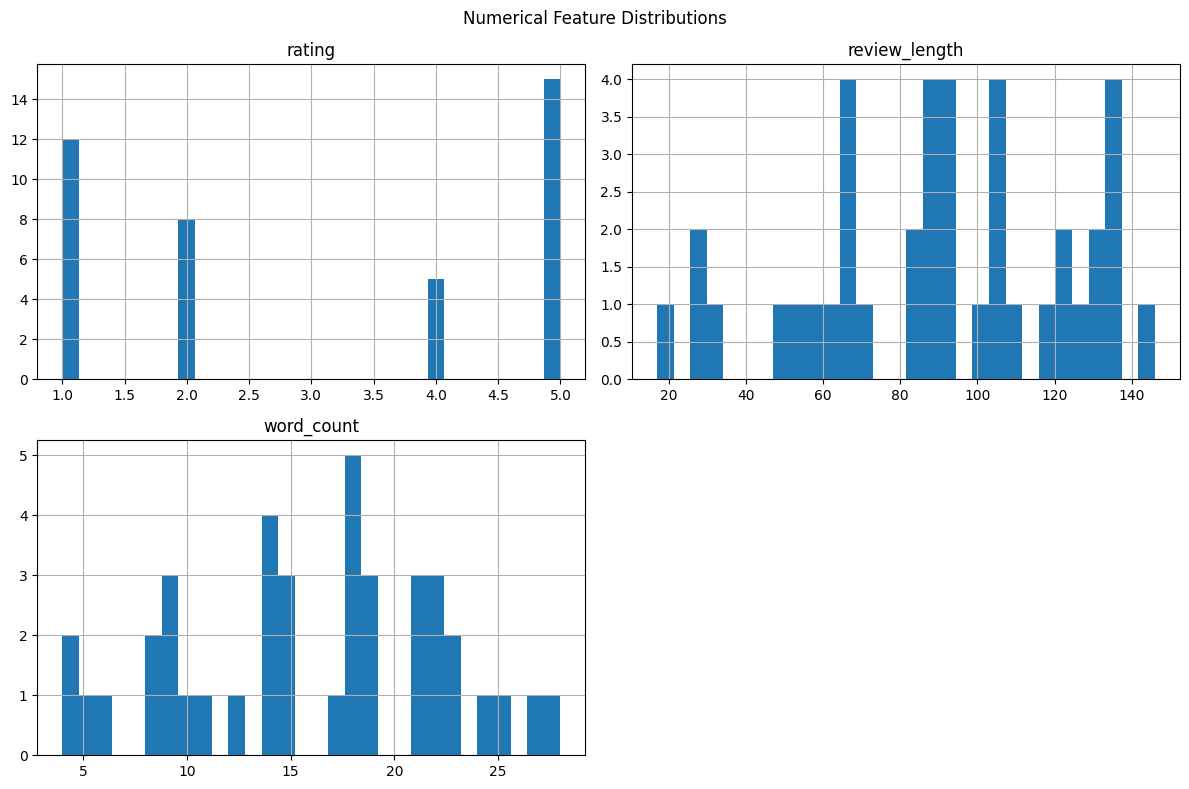

In [88]:
df[numeric_features].hist(
    figsize=(12, 8),
    bins=30
)

plt.suptitle("Numerical Feature Distributions")
plt.tight_layout()
plt.show()

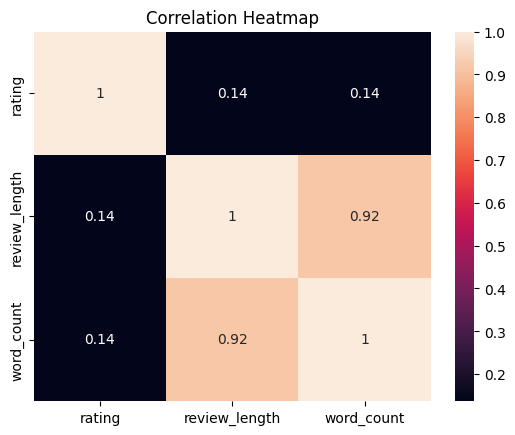

In [89]:
#Correlation Heatmap

import seaborn as sns
import matplotlib.pyplot as plt

sns.heatmap(df[['rating','review_length','word_count']].corr(),
            annot=True)
plt.title("Correlation Heatmap")
plt.show()

In [92]:

# LOGISTIC REGRESSION

lr = LogisticRegression(random_state=42, max_iter=1000)
lr.fit(X_train_vectorized, y_train)
y_pred_lr = lr.predict(X_test_vectorized)

In [93]:
lr_accuracy = accuracy_score(y_test, y_pred_lr)
lr_precision = precision_score(y_test, y_pred_lr, average="weighted", zero_division=0)
lr_recall = recall_score(y_test, y_pred_lr, average="weighted", zero_division=0)
lr_f1 = f1_score(y_test, y_pred_lr, average="weighted", zero_division=0)

In [94]:

# RANDOM FOREST

rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf.fit(X_train_vectorized, y_train)
y_pred_rf = rf.predict(X_test_vectorized)

In [95]:
rf_accuracy = accuracy_score(y_test, y_pred_rf)
rf_precision = precision_score(y_test, y_pred_rf, average="weighted", zero_division=0)
rf_recall = recall_score(y_test, y_pred_rf, average="weighted", zero_division=0)
rf_f1 = f1_score(y_test, y_pred_rf, average="weighted", zero_division=0)

In [96]:

# MODEL COMPARISON

results = pd.DataFrame({
    "Model": ["Multinomial Naive Bayes", "Logistic Regression", "Random Forest"],
    "Accuracy": [accuracy_score, lr_accuracy, rf_accuracy],
    "Precision": [precision, lr_precision, rf_precision],
    "Recall": [recall, lr_recall, rf_recall],
    "F1 Score": [f1, lr_f1, rf_f1]
})

In [97]:
print("\n========================================")
print("          MODEL COMPARISON")
print("==========================================")
print(results.round(4))


          MODEL COMPARISON
                     Model                                     Accuracy  \
0  Multinomial Naive Bayes  <function accuracy_score at 0x7b5af5fec180>   
1      Logistic Regression                                         0.75   
2            Random Forest                                        0.625   

   Precision  Recall  F1 Score  
0     0.8333   0.750    0.7333  
1     0.8333   0.750    0.7333  
2     0.7857   0.625    0.5636  


In [99]:
print("\n========================================")
print("         REAL-TIME PREDICTION")
print("========================================")

input_text = input("Enter text/review for prediction: ")

# Convert input into a Series
new_sample = pd.Series([input_text])

# Transform text using the trained vectorizer
new_sample_vectorized = vectorizer.transform(new_sample)

# Prediction and probability
prediction = model.predict(new_sample_vectorized)
probability = model.predict_proba(new_sample_vectorized)

confidence = np.max(probability) * 100

# Display results
print("\n========================================")
print(f"Predicted Class : {prediction[0]}")
print(f"Confidence      : {confidence:.2f}%")
print("========================================")


         REAL-TIME PREDICTION
Enter text/review for prediction: Good Product ....

Predicted Class : positive
Confidence      : 74.50%
